In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
df = pd.read_csv("melb_data.csv")

print("Informasi dataset")
print(df.info(), "\n")

print("Statistik deskriptif")
print(df.describe(), "\n")

print("5 data teratas")
print(df.head(), "\n")

print("Jumlah missing values")
print(df.isnull().sum(), "\n")

print("Ukuran dataset (baris, kolom): ", df.shape[0], ",", df.shape[1])

Informasi dataset
<class 'pandas.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         13580 non-null  str    
 1   Address        13580 non-null  str    
 2   Rooms          13580 non-null  int64  
 3   Type           13580 non-null  str    
 4   Price          13580 non-null  float64
 5   Method         13580 non-null  str    
 6   SellerG        13580 non-null  str    
 7   Date           13580 non-null  str    
 8   Distance       13580 non-null  float64
 9   Postcode       13580 non-null  float64
 10  Bedroom2       13580 non-null  float64
 11  Bathroom       13580 non-null  float64
 12  Car            13518 non-null  float64
 13  Landsize       13580 non-null  float64
 14  BuildingArea   7130 non-null   float64
 15  YearBuilt      8205 non-null   float64
 16  CouncilArea    12211 non-null  str    
 17  Lattitude      13580 non-null  float64
 18 

In [3]:
# Handle missing values

# Buang kolom BuildingArea & YearBuilt karena kebanyakan bolongnya
df_cleaned = df.drop(columns=['BuildingArea', 'YearBuilt'])

# Hapus MS dari kolom Car & CouncilArea
df_cleaned = df_cleaned.dropna()

print("Sisa missing values setelah dibersihkan")
print(df_cleaned.isnull().sum())
print(f"\nJumlah data asli : {len(df)}")
print(f"Jumlah data setelah data cleaning : {len(df_cleaned)}")

Sisa missing values setelah dibersihkan
Suburb           0
Address          0
Rooms            0
Type             0
Price            0
Method           0
SellerG          0
Date             0
Distance         0
Postcode         0
Bedroom2         0
Bathroom         0
Car              0
Landsize         0
CouncilArea      0
Lattitude        0
Longtitude       0
Regionname       0
Propertycount    0
dtype: int64

Jumlah data asli : 13580
Jumlah data setelah data cleaning : 12211


In [10]:
# one hot encoding
df_encoded = pd.get_dummies(df_cleaned, columns=['Type', 'Regionname'], drop_first=True)

# feature engineering
cols_to_drop = [
    'Address',
    "Suburb",
    'Method',
    "SellerG",
    "Date",
    'Price',
    'CouncilArea',
]

X = df_encoded.drop(columns=cols_to_drop)
y = df_encoded['Price']

print(f"Jumlah fitur setelah on hot encoding : {X.shape[1]}")

Jumlah fitur setelah on hot encoding : 19


In [ ]:
# Feature selection
'''selected_features = [
    'Rooms',
    'Distance',
    'Bedroom2',
    'Bathroom',
    'Car',
    'Landsize',
    'Lattitude',
    'Longtitude'
]

X = df_cleaned[selected_features]
y = df_cleaned['Price']
'''

In [ ]:
# Data testing & traning
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)

rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))

print("Evaluasi model (setelah one hot encoding)")
print("R2 Score")
print(f"Train :  {r2_train * 100:.2f}%")
print(f"Test :  {r2_test * 100:.2f}%")
print()
print("RMSE")
print(f"Train :  {rmse_train * 100:.2f}%")
print(f"Test :  {rmse_test * 100:.2f}%")

Evaluasi model (setelah one hot encoding)
R2 Score
Train :  59.51%
Test :  58.76%

RMSE
Train :  40186804.49%
Test :  42810964.08%

performa modelnya jelek banget


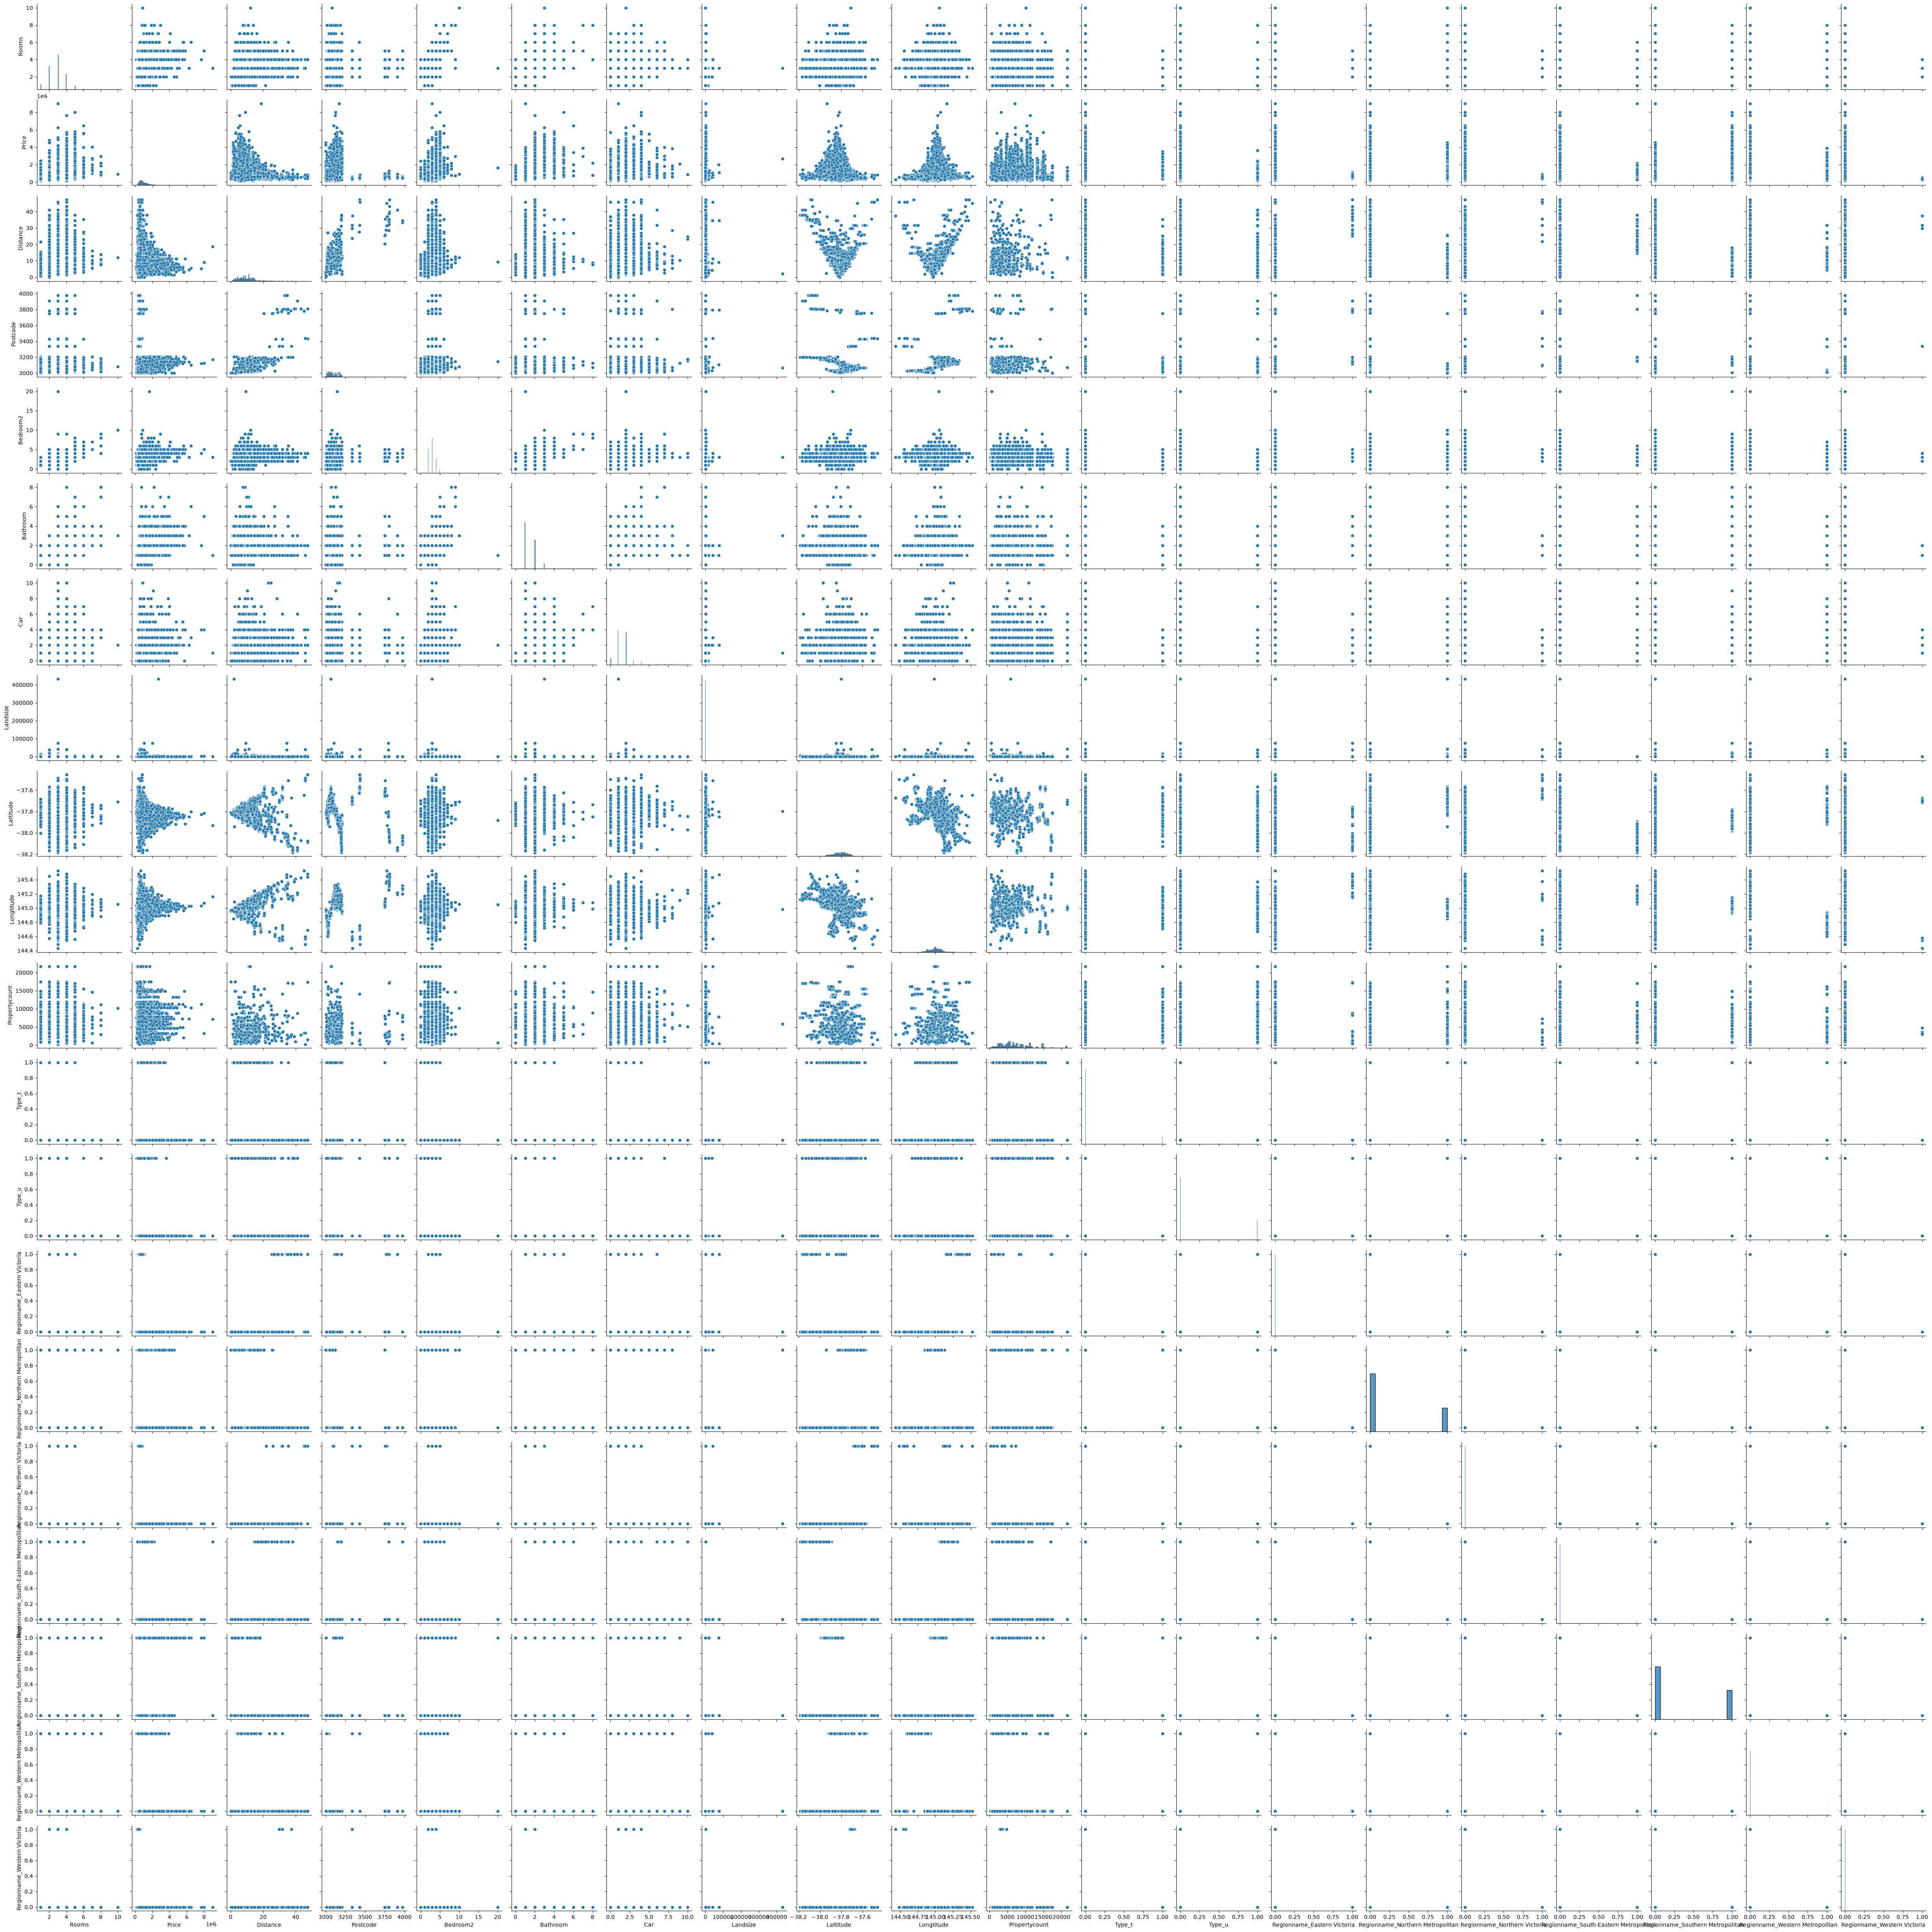

In [13]:
sns.pairplot(df_encoded)

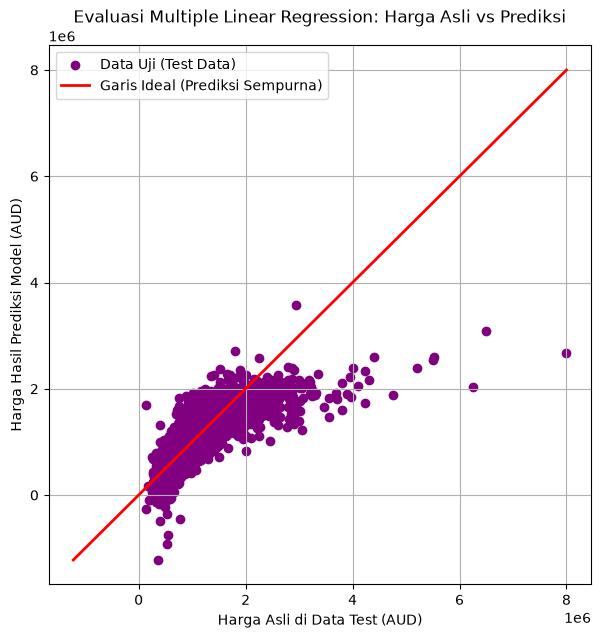

In [ ]:
plt.figure(figsize=(7, 7))
plt.scatter(
    y_test,
    y_pred_test,
    color="purple",
    label="Data Uji (Test Data)",
)

# Garis ideal (Prediksi Sempurna)
min_val = min(min(y_test), min(y_pred_test))
max_val = max(max(y_test), max(y_pred_test))
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linewidth=2,
    label="Garis Ideal (Prediksi Sempurna)",
)

plt.title("Evaluasi Linear Regression + One Hot Encoding: Harga Asli vs Prediksi")
plt.xlabel("Harga Asli di Data Test (AUD)")
plt.ylabel("Harga Hasil Prediksi Model (AUD)")
plt.legend()
plt.grid(True)
plt.show()